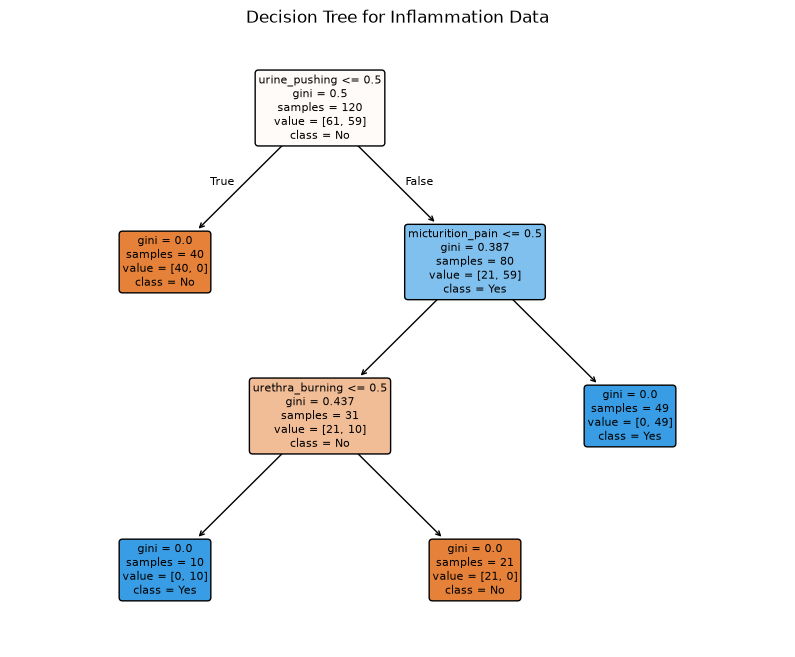

In [109]:
#1b Build a decision tree on the whole data set and plot it 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

columns = [
    "temperature", "nausea", "lumbar_pain", 
    "urine_pushing", "micturition_pain", "urethra_burning", 
    "bladder_inflammation", "nephritis"
]

df = pd.read_csv('acute+inflammations/diagnosis.data', 
                 sep='\t', 
                 header=None, 
                 names=columns, 
                 encoding='utf-16', 
                 decimal=',')
df.head()

# converting categorical to numeric
for col in df.columns[1:]:
    df[col] = df[col].map({'yes': 1, 'no': 0}).astype(int)
X = df.iloc[:, :6]
y = df['bladder_inflammation']

#tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X,y)

plt.figure(figsize=(10,8))
plot_tree(
    dt, feature_names=X.columns, 
    class_names = ['No', 'Yes'],
    filled=True, 
    rounded=True, 
    fontsize=8
)

plt.title('Decision Tree for Inflammation Data')
plt.show()

In [110]:
#1c Convert the decision rules into a set of IF-THEN rules
from sklearn.tree import export_text

rules = export_text(dt, feature_names=list(X.columns))
print(rules)

|--- urine_pushing <= 0.50
|   |--- class: 0
|--- urine_pushing >  0.50
|   |--- micturition_pain <= 0.50
|   |   |--- urethra_burning <= 0.50
|   |   |   |--- class: 1
|   |   |--- urethra_burning >  0.50
|   |   |   |--- class: 0
|   |--- micturition_pain >  0.50
|   |   |--- class: 1



CCP Alphas: [0.         0.11290323 0.14522177 0.24173611] 

      alpha  accuracy  leaves  depth
0  0.000000  1.000000       4      3
1  0.112903  0.783333       3      2
2  0.145222  0.808333       2      1
3  0.241736  0.708333       1      0 

Best alpha:  0.0
# of leaves:  4
Tree depth:  3


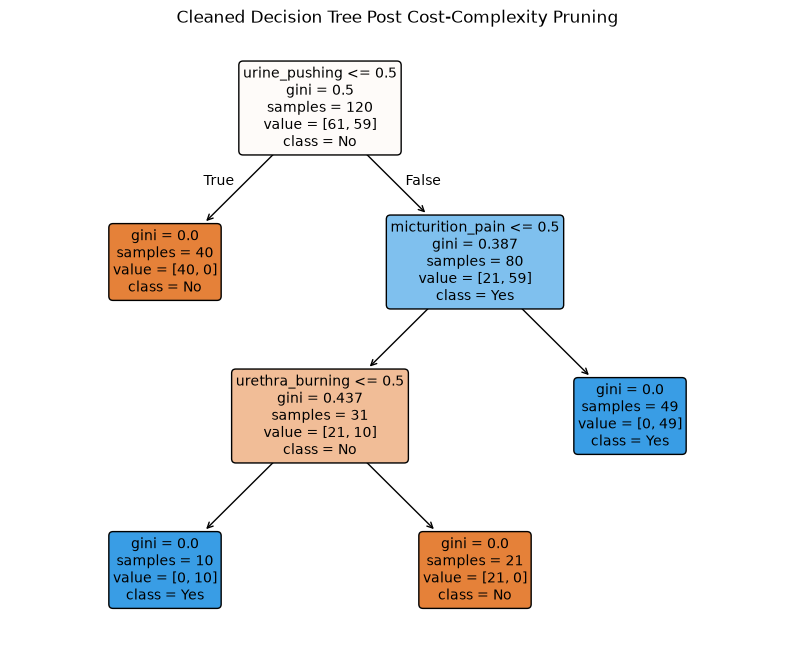

|--- urine_pushing <= 0.50
|   |--- class: 0
|--- urine_pushing >  0.50
|   |--- micturition_pain <= 0.50
|   |   |--- urethra_burning <= 0.50
|   |   |   |--- class: 1
|   |   |--- urethra_burning >  0.50
|   |   |   |--- class: 0
|   |--- micturition_pain >  0.50
|   |   |--- class: 1

Initial leaves:  4
Pruned leaves:  4
Initial depth:  3
Pruned depth:  3


In [111]:
#1d Use cost-complexity pruning to find a minimal decision tree and a set of decision 
# rules with high interpretability
path = dt.cost_complexity_pruning_path(X,y)
ccp_alphas = path.ccp_alphas
print("CCP Alphas:", ccp_alphas, "\n")


from sklearn.model_selection import cross_val_score
results =[]

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, 
    ccp_alpha=alpha)

    scores = cross_val_score(tree, X, y, cv=5)
    tree.fit(X,y)
    results.append({
        'alpha':alpha,
        'accuracy': scores.mean(), 
        'leaves': tree.get_n_leaves(),
        'depth': tree.get_depth()
    })
results_df = pd.DataFrame(results)
print(results_df, "\n")


#best one selection
best = results_df.sort_values(
    by=["accuracy", 'leaves', 'depth'],
    ascending=[False, True, True]
).iloc[0]

best_alpha = best['alpha']

cleaned_dt = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)
cleaned_dt.fit(X,y)
print("Best alpha: ", best_alpha)
print("# of leaves: ", cleaned_dt.get_n_leaves())
print("Tree depth: ", cleaned_dt.get_depth())


#plotting 
plt.figure(figsize=(10,8))

plot_tree(
    cleaned_dt,
    feature_names = X.columns,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Cleaned Decision Tree Post Cost-Complexity Pruning")
plt.show()

# identifying if-then rules
pruned_rules=export_text(
    cleaned_dt, 
    feature_names=list(X.columns)
)
print(pruned_rules) # new rules 

print("Initial leaves: ", dt.get_n_leaves())
print("Pruned leaves: ", cleaned_dt.get_n_leaves())

print('Initial depth: ', dt.get_depth())
print("Pruned depth: ", cleaned_dt.get_depth())

#1d interpretation
The leaves did not change in number, remaining 4 to 4. The selected tree kept the original structure, leaving the interpretation that there was no more pruning needed to improve the chosen balance between accuracy and interpretability. 

In [112]:
#2b Use a data imputation technique to deal with
# the missing values in the data set. The data description mentions some features
# are nonpredictive. Ignore those features.
import pandas as pd
from sklearn.impute import SimpleImputer

df = pd.read_csv('communities.data', header=None, na_values='?')

print(df.shape)
print(df.isna().sum().sum())

#remove nonpredictive features
df = df.drop(columns=[0,1,2,3,4])
print(df.shape)

#missing values
y = df.iloc[:, -1]

X = X.dropna(axis=1, how='all')
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values before: ", X.isna().sum().sum())
print("Missing values after: ", X_imputed.isna().sum().sum())
print("Final shape: ", X_imputed.shape)

(1994, 128)
39202
(1994, 123)
Missing values before:  0
Missing values after:  0
Final shape:  (120, 6)


                  temperature    nausea  lumbar_pain  urine_pushing  \
temperature          1.000000  0.593152     0.391971      -0.018866   
nausea               0.593152  1.000000     0.477105      -0.013765   
lumbar_pain          0.391971  0.477105     1.000000      -0.239046   
urine_pushing       -0.018866 -0.013765    -0.239046       1.000000   
micturition_pain     0.060493  0.574007    -0.183142       0.341816   
urethra_burning      0.037245 -0.121744     0.028571       0.597614   

                  micturition_pain  urethra_burning  
temperature               0.060493         0.037245  
nausea                    0.574007        -0.121744  
lumbar_pain              -0.183142         0.028571  
urine_pushing             0.341816         0.597614  
micturition_pain          1.000000         0.149331  
urethra_burning           0.149331         1.000000  


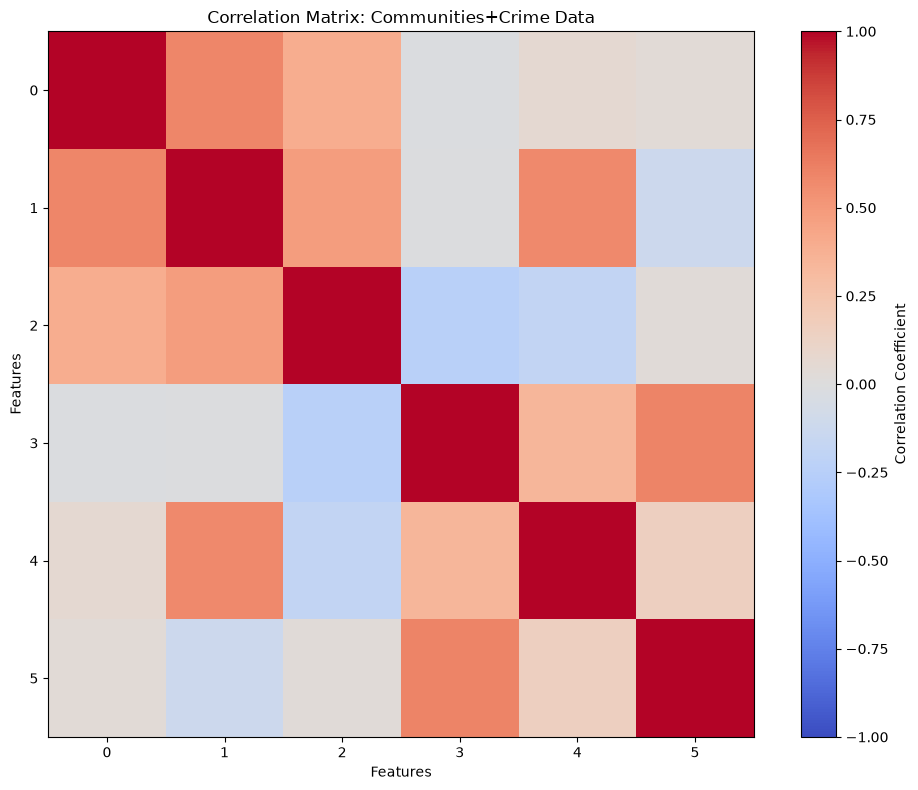

urine_pushing     urethra_burning     0.597614
temperature       nausea              0.593152
nausea            micturition_pain    0.574007
                  lumbar_pain         0.477105
temperature       lumbar_pain         0.391971
urine_pushing     micturition_pain    0.341816
lumbar_pain       urine_pushing       0.239046
                  micturition_pain    0.183142
micturition_pain  urethra_burning     0.149331
nausea            urethra_burning     0.121744
dtype: float64


In [113]:
#2c plot a correlation matrix for the features in the data set

corr_matrix = X_imputed.corr()
print(corr_matrix)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
plt.imshow(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
plt.colorbar(label='Correlation Coefficient')
plt.title("Correlation Matrix: Communities+Crime Data")
plt.xlabel('Features')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

# strongest corr
import numpy as np
cleaning = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
correlations = corr_matrix.where(cleaning).stack()
print(correlations.abs().sort_values(ascending=False).head(10))


In [114]:
#2d calculate the Coefficient of Variation CV for each feature, where 
# where CV = s / m, in which s is sample standard deviation and m is sample mean

std = X_imputed.std(ddof=1)
mean=X_imputed.mean()

cv = std/mean

cv_df = pd.DataFrame({
    "Mean": mean,
    "Standard Deviation": std,
    "CV": cv
})
sorted_cv = cv_df.sort_values(by="CV", ascending=False)
print(sorted_cv)


                       Mean  Standard Deviation        CV
nausea             0.241667            0.429888  1.778848
urethra_burning    0.416667            0.495074  1.188177
micturition_pain   0.491667            0.502027  1.021071
lumbar_pain        0.583333            0.495074  0.848698
urine_pushing      0.666667            0.473381  0.710072
temperature       38.724167            1.819132  0.046977


Selected features: [113, 95, 94, 54, 56, 125, 32, 5, 101, 15, 76]
X_top shape: (1994, 11)
y_crime shape: (1994,)


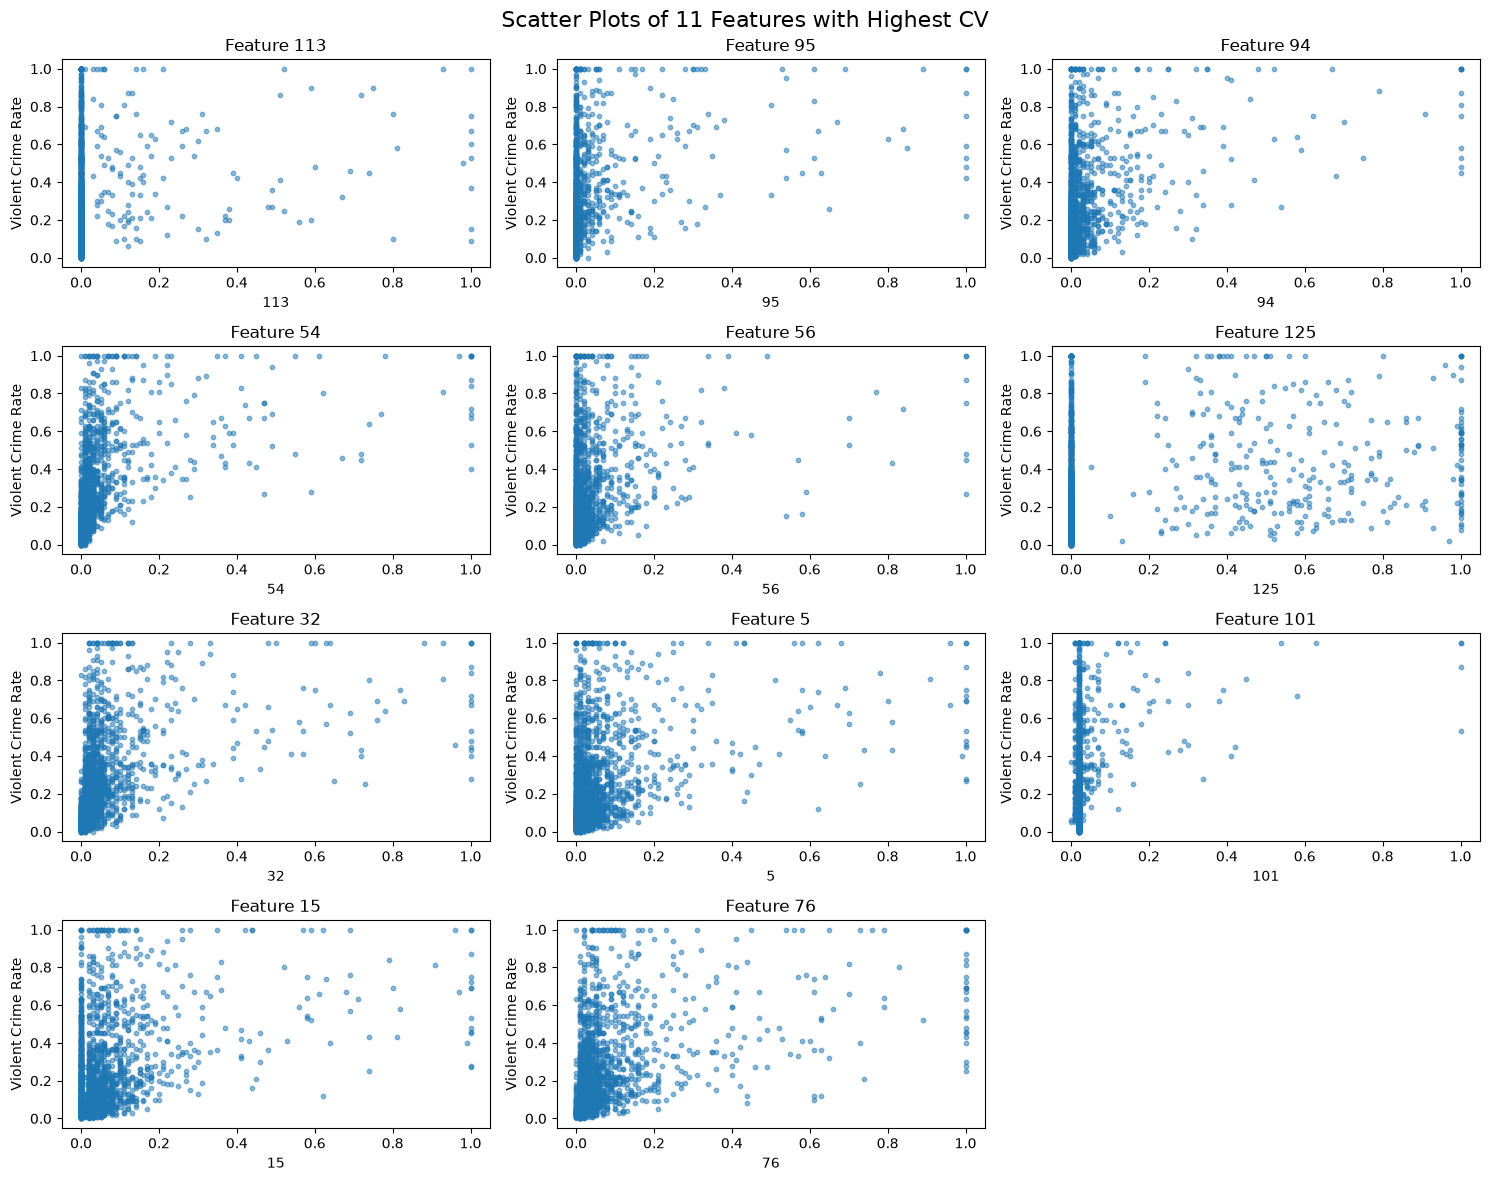

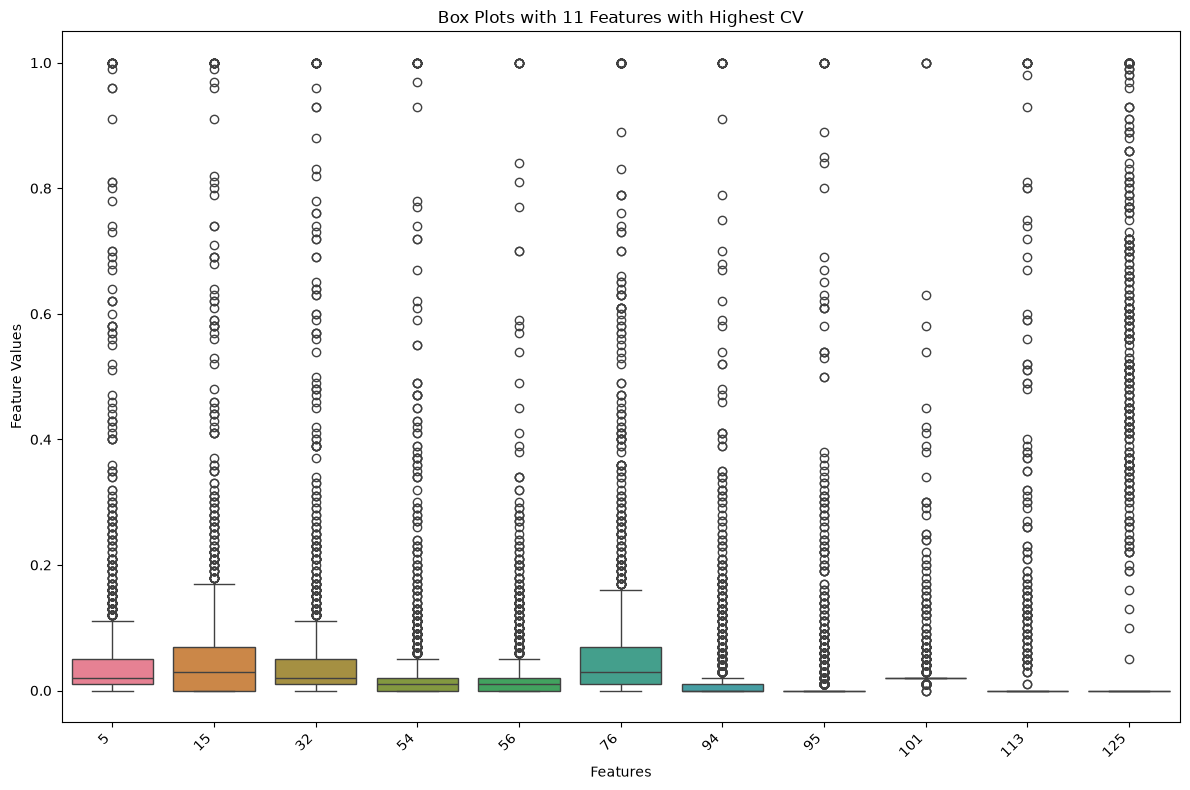

In [117]:
#2e pick square root 128 features with highest CV, and make scatter plots and box plots
# for them
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer

# Load Communities and Crime dataset
crime_df = pd.read_csv(
    'communities.data',
    header=None,
    na_values='?'
)

# Remove nonpredictive features
crime_df = crime_df.drop(columns=[0, 1, 2, 3, 4])

# Separate predictors and target
X_crime = crime_df.iloc[:, :-1]
y_crime = crime_df.iloc[:, -1]

# Remove features with all missing values
X_crime = X_crime.dropna(axis=1, how='all')

# Median imputation
imputer = SimpleImputer(strategy='median')

X_crime_imputed = pd.DataFrame(
    imputer.fit_transform(X_crime),
    columns=X_crime.columns,
    index=X_crime.index
)

# Calculate coefficient of variation
cv_2e = (
    X_crime_imputed.std(ddof=1)
    / X_crime_imputed.mean()
)

# Select top 11 features
n = int(np.sqrt(128))
top_features = cv_2e.nlargest(n).index

X_top = X_crime_imputed[top_features]

print("Selected features:", list(top_features))
print("X_top shape:", X_top.shape)
print("y_crime shape:", y_crime.shape)

# Scatter plots
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_top[feature],
        y_crime,
        alpha=0.5,
        s=10
    )
    axes[i].set_title(f'Feature {feature}')
    axes[i].set_xlabel(str(feature))
    axes[i].set_ylabel('Violent Crime Rate')

# Remove unused subplots
for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    'Scatter Plots of 11 Features with Highest CV',
    fontsize=16
)
plt.tight_layout()
plt.show()

# Box plots
plt.figure(figsize=(12, 8))
sns.boxplot(data=X_top)

plt.title('Box Plots with 11 Features with Highest CV')
plt.xlabel('Features')
plt.ylabel('Feature Values')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


#2e Can you draw conclusions about significance of those features, just by the scatter plots?
The scatter plots can show potential relationships between the chosen features and violent crime rates. On the other hand, the statistical significance can't be proven purely based on visuals. It can be said to illustrate stronger trends, visually, but there would need to be more analysis in order to determine significance.  

In [ ]:
#2f Fit a linear model using least squares to the training set and report the test error.

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

#training + testing
X_train, X_test, y_train, y_test = train_test_split(
    X_crime_imputed, 
    y_crime, 
    test_size=0.2, # testing gets 20% of split, 80% training 
    random_state=42
)

#fitting least_squares linear regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)

#mse calculation
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

#results
print("Training MSE:", train_mse)
print("Testing MSE:", test_mse)

Training MSE: 0.0162001031541877
Testing MSE: 0.018127777876228806


In [129]:
#2g Fit a ridge regression model on the training set, with chosen by cross-validation. 
# report the test error obtained.
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# defining lambda values
lambdas = np.logspace(-4, 4, 50)

# ridge regression model
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge()
)

# 5-fold CV for selcting lambda
ridge_cv = GridSearchCV(
    ridge_model,
    param_grid={'ridge__alpha': lambdas},
    cv=5,
    scoring='neg_mean_squared_error'
)

# fitting model with training data 
ridge_cv.fit(X_train, y_train)
y_pred_ridge = ridge_cv.predict(X_test) # predicting using test data

# identifying test error
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)

#results 
print("Best lambda:", ridge_cv.best_params_['ridge__alpha'])
print("Ridge Test MSE:", ridge_test_mse)


Best lambda: 159.98587196060572
Ridge Test MSE: 0.017570884267095147


In [ ]:
#2h Fit a LASSO model on the training set, with chosen by cross-validation. Report test
# error obtained, along with a list of the variables selected by the model. 
# Repeat with standardized features
# Report the test error for both cases and compare them. 
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# defining lambda values
lambdas = np.logspace(-5, 1, 50)

# LASSO w/o standardization
lasso_model = Lasso(max_iter=100000)

lasso_cv = GridSearchCV(
    lasso_model,
    param_grid={'alpha': lambdas},
    cv=5,
    scoring='neg_mean_squared_error'
)

lasso_cv.fit(X_train, y_train)
#predicting with test data 
y_pred_lasso = lasso_cv.predict(X_test)
lasso_test_mse = mean_squared_error(y_test, y_pred_lasso) # test error 

# selected variables (nonzero Coeffs)
lasso_coef = lasso_cv.best_estimator_.coef_
lasso_selected = X_train.columns[abs(lasso_coef) > 1e-6]

print("LASSO Without Standardization")
print("Best lambda:", lasso_cv.best_params_['alpha'])
print("Test MSE:", lasso_test_mse)
print("# of selected variables:", len(lasso_selected))
print("Selected variables:", list(lasso_selected))


# PT 2: LASSO w/ standardized features
lasso_scaled_model = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=100000)
)

lasso_scaled_cv = GridSearchCV(
    lasso_scaled_model,
    param_grid={'lasso__alpha': lambdas},
    cv=5,
    scoring='neg_mean_squared_error'
)
#fitting model with training data 
lasso_scaled_cv.fit(X_train, y_train)
# prediction with test data 
y_pred_lasso_scaled = lasso_scaled_cv.predict(X_test)

#test error 
lasso_scaled_test_mse = mean_squared_error(
    y_test,
    y_pred_lasso_scaled
)

# Identify selected variables
lasso_scaled_coef = lasso_scaled_cv.best_estimator_.named_steps['lasso'].coef_
lasso_scaled_selected = X_train.columns[abs(lasso_scaled_coef) > 1e-6]

#results 
print("\nLASSO With Standardization")
print("Best lambda:", lasso_scaled_cv.best_params_['lasso__alpha'])
print("Test MSE:", lasso_scaled_test_mse)
print("Number of selected variables:", len(lasso_scaled_selected))
print("Selected variables:", list(lasso_scaled_selected))


# comparing test errors from pt 1 and pt 2
print("\nComparison of Test Errors")
print("Without Standardization:", lasso_test_mse)
print("With Standardization:", lasso_scaled_test_mse)

if lasso_scaled_test_mse < lasso_test_mse:
    print("Standardized LASSO has lower test error.")
elif lasso_scaled_test_mse > lasso_test_mse:
    print("Unstandardized LASSO has lower test error.")
else:
    print("Both models have equal test error.")


LASSO Without Standardization
Best lambda: 0.0006866488450042998
Test MSE: 0.017300525133694438
# of selected variables: 29
Selected variables: [7, 8, 12, 16, 18, 20, 29, 30, 31, 39, 43, 49, 50, 53, 55, 73, 76, 77, 79, 91, 93, 95, 96, 99, 109, 110, 111, 113, 125]

LASSO With Standardization
Best lambda: 0.004941713361323833
Test MSE: 0.017384209352014835
Number of selected variables: 27
Selected variables: [7, 8, 12, 16, 20, 29, 30, 39, 43, 49, 50, 53, 55, 73, 76, 77, 79, 91, 93, 95, 96, 107, 109, 110, 111, 113, 125]

Comparison of Test Errors
Without Standardization: 0.017300525133694438
With Standardization: 0.017384209352014835
Unstandardized LASSO has lower test error.


In [131]:
#2i Fit a PCR model on the training set, with M (the number of principal components) chosen
# by cross-validation. Report the test error obtained. 
#my notes --> principal component analysis -- reduces # of predictors into principal components
#             linear reg -- uses PC to predict crime rate 

import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

pcr_model = make_pipeline(
    StandardScaler(),
    PCA(),
    LinearRegression()
)

# defining # of PCs to test
components = range(1, X_train.shape[1] + 1)

# using 5-fold CV to select M
pcr_cv = GridSearchCV(
    pcr_model,
    param_grid={'pca__n_components': components},
    cv=5,
    scoring='neg_mean_squared_error'
)

# fitting PCR model w/ training data
pcr_cv.fit(X_train, y_train)
y_pred_pcr = pcr_cv.predict(X_test) # predict with test data 
pcr_test_mse = mean_squared_error(y_test, y_pred_pcr) # test error

# Report results
print("Best M:", pcr_cv.best_params_['pca__n_components'])
print("PCR Test MSE:", pcr_test_mse)

Best M: 86
PCR Test MSE: 0.018719028878999972


#2i interpretation
Principal Component Regression was fitted using standardized predictors, with the number of principal components chosen through the five-fold cross-validation. From this, it was concluded that the best number of components was M = 86, with a PCR Test mean squared error of approximately 0.018719. 

In [133]:
#2j In this section, we would like to fit a boosting tree to the data. In the classification
# trees, one can use any type of regression at each node to build a multivariate regression tree. 
# Because the number of variables is large in this problem, one can use L1 penalized 
# regression at each node. etc. 

import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

boost_model = GradientBoostingRegressor(random_state=42)

# choosing # of trees with CV
boost_cv = GridSearchCV(
    boost_model,
    param_grid={
        'n_estimators': [100, 200, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [2, 3]
    },
    cv=5,
    scoring='neg_mean_squared_error'
)

# fitting with training data 
boost_cv.fit(X_train, y_train)

# predicting onto test data
y_pred_boost = boost_cv.predict(X_test)
boost_test_mse = mean_squared_error(y_test, y_pred_boost) # test error

print("Best parameters:", boost_cv.best_params_)
print("Boosting Test MSE:", boost_test_mse)


Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
Boosting Test MSE: 0.01921021900033861


#2j For the gradient-boosted regression tree model, a 5-fold CV was utilized to select the optimal hyperparameters. The chosen model used a learning rate of 0.05, maximum tree depth of 3 and then 200 trees. The concluding test mean squared error (MSE) was approximately 0.01921, illustrating an averaged squared prediction error on the test set. 